# Model Building

## Imports 

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data

In [2]:
# 1. Original molecular descriptor names
feature_names = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]",
    "NssssC", "nCb-", "C%", "nCp", "nO",
    "F03[C-N]", "SdssC", "HyWi_B(m)", "LOC", "SM6_L",
    "F03[C-O]", "Me", "Mi", "nN-N", "nArNO2",
    "nCRX3", "SpPosA_B(p)", "nCIR", "B01[C-Br]",
    "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d",
    "B04[C-Br]", "SdO", "TI2_L", "nCrt",
    "C-026", "F02[C-N]", "nHDon", "SpMax_B(m)",
    "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX"
]

# 2. Load the dataset
df = pd.read_csv(
    "../data/biodeg.csv",
    sep=";",
    header=None,
    names=feature_names + ["biodegradable"]
)

# 3. Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 4. Clean column names for XGBoost
def clean_feature_name(name):
    return (
        name.replace("[", "_")
            .replace("]", "")
            .replace("<", "_")
    )

df = df.rename(columns=clean_feature_name)

# 5. Create features and target
X = df.drop(columns=["biodegradable"])
y = df["biodegradable"].map({"NRB": 0, "RB": 1})

# 6. Create training / validation / test splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# 7. Verify
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

assert not any(
    any(char in col for char in "[]<")
    for col in X_train.columns
)


Training: (631, 41)
Validation: (210, 41)
Test: (211, 41)


## Model #1: Logistic Regression

In [4]:
# first pass
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    )
)

model_lr.fit(X_train, y_train)

# Predict probability of ready biodegradability
y_pred = model_lr.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f"Validation ROC-AUC: {auc:.4f}")


Validation ROC-AUC: 0.9204


In [5]:
# tune regularizarion parameter C. It seems C=1 is the best so far
results_lr = []

for C in [0.01, 0.1, 1, 10, 100]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=2000,
            random_state=42
        )
    )

    model.fit(X_train, y_train)

    # Training ROC-AUC
    y_train_pred = model.predict_proba(X_train)[:, 1]
    train_auc = roc_auc_score(y_train, y_train_pred)

    # Validation ROC-AUC
    y_val_pred = model.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, y_val_pred)

    results_lr.append({
        "C": C,
        "train_auc": train_auc,
        "val_auc": val_auc
    })

df_results_lr = pd.DataFrame(results_lr)

df_results_lr = df_results_lr.sort_values(
    "val_auc", ascending=False
)

display(df_results_lr)


,C,train_auc,val_auc
2,1.00,0.954350,0.920357
3,10.00,0.957153,0.916810
1,0.10,0.947640,0.913568
4,100.00,0.957964,0.913365
0,0.01,0.928986,0.893809


In [6]:
best_lr = df_results_lr.iloc[0]

best_lr_C = float(best_lr["C"])
best_lr_auc = float(best_lr["val_auc"])

print(f"Best C: {best_lr_C}")
print(f"Best validation ROC-AUC: {best_lr_auc:.4f}")

Best C: 1.0
Best validation ROC-AUC: 0.9204


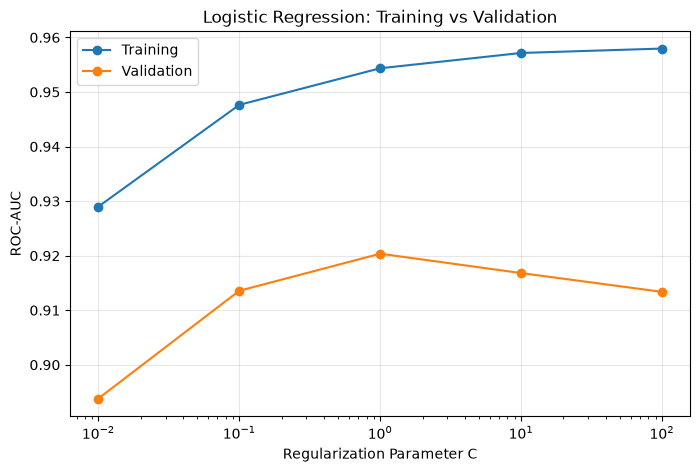

In [7]:
df_plot_lr = df_results_lr.sort_values("C")

plt.figure(figsize=(8, 5))

plt.semilogx(
    df_plot_lr["C"],
    df_plot_lr["train_auc"],
    marker="o",
    label="Training"
)

plt.semilogx(
    df_plot_lr["C"],
    df_plot_lr["val_auc"],
    marker="o",
    label="Validation"
)

plt.xlabel("Regularization Parameter C")
plt.ylabel("ROC-AUC")
plt.title("Logistic Regression: Training vs Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Model #2: Decision Tree

In [8]:
model_dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model_dt.fit(X_train, y_train)

# Predicted probabilities
y_pred = model_dt.predict_proba(X_val)[:, 1]

# Validation ROC-AUC
auc = roc_auc_score(y_val, y_pred)

print(f"Decision Tree ROC-AUC: {auc:.4f}")

Decision Tree ROC-AUC: 0.8089


In [9]:
# tune hyper parameters

results_dt = []

for depth in [2, 3, 4, 5, 6, 8, None]:
    for min_leaf in [1, 5, 10, 20]:

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=42
        )

        model.fit(X_train, y_train)

        # Training performance
        y_train_pred = model.predict_proba(X_train)[:, 1]
        train_auc = roc_auc_score(y_train, y_train_pred)

        # Validation performance
        y_val_pred = model.predict_proba(X_val)[:, 1]
        val_auc = roc_auc_score(y_val, y_val_pred)

        results_dt.append({
            "max_depth": depth,
            "min_samples_leaf": min_leaf,
            "train_auc": train_auc,
            "val_auc": val_auc
        })

In [10]:
df_results_dt = pd.DataFrame(results_dt)

df_results_dt = df_results_dt.sort_values(
    "val_auc",
    ascending=False
)

display(df_results_dt.head(10))

,max_depth,min_samples_leaf,train_auc,val_auc
19,6.0,20,0.932471,0.848718
27,NaN,20,0.937143,0.843905
23,8.0,20,0.937143,0.843905
18,6.0,10,0.959022,0.835596
15,5.0,20,0.922063,0.834380
22,8.0,10,0.969779,0.829567
26,NaN,10,0.970927,0.829263
21,8.0,5,0.980530,0.827186
17,6.0,5,0.961859,0.826528
7,3.0,20,0.878698,0.825869


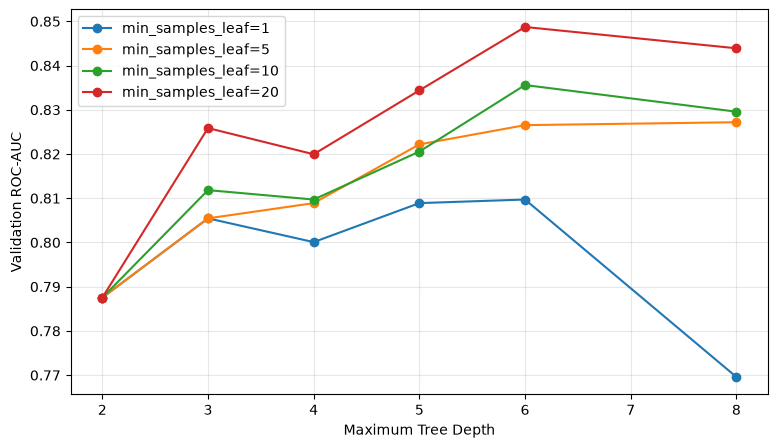

In [11]:
plt.figure(figsize=(9, 5))

for min_leaf in [1, 5, 10, 20]:
    subset = df_results_dt[
        df_results_dt["min_samples_leaf"] == min_leaf
    ].copy()

    # Omit unlimited-depth trees from this plot
    subset = subset[subset["max_depth"].notna()]
    subset = subset.sort_values("max_depth")

    plt.plot(
        subset["max_depth"],
        subset["val_auc"],
        marker="o",
        label=f"min_samples_leaf={min_leaf}"
    )

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Validation ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
# pick best tree
best_params_dt = df_results_dt.iloc[0]

best_depth = (
    None if pd.isna(best_params_dt["max_depth"])
    else int(best_params_dt["max_depth"])
)

best_min_leaf = int(best_params_dt["min_samples_leaf"])

best_dt = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_min_leaf,
    random_state=42
)

best_dt.fit(X_train, y_train)

print("Best depth:", best_depth)
print("Best min_samples_leaf:", best_min_leaf)
print(f"Best validation ROC-AUC: {best_params_dt['val_auc']:.4f}")

Best depth: 6
Best min_samples_leaf: 20
Best validation ROC-AUC: 0.8487


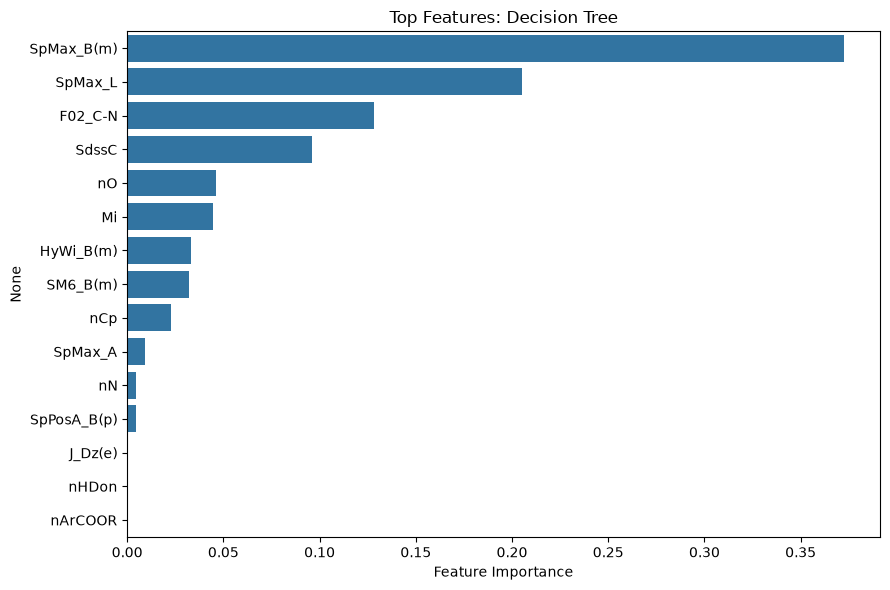

In [13]:
# examine feature importance
feature_importance_dt = pd.Series(
    best_dt.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=feature_importance_dt.head(15).values,
    y=feature_importance_dt.head(15).index
)

plt.xlabel("Feature Importance")
plt.title("Top Features: Decision Tree")
plt.tight_layout()
plt.show()

In [14]:
#combine result dataframes
model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "val_auc": df_results_lr.iloc[0]["val_auc"],
        "hyperparameters": {
            "C": best_lr_C
        }
    },
    {
        "model": "Decision Tree",
        "val_auc": df_results_dt.iloc[0]["val_auc"],
        "hyperparameters": {
            "max_depth": best_depth,
            "min_samples_leaf": best_min_leaf
        }
    }
])

model_comparison = model_comparison.sort_values(
    "val_auc", ascending=False
)

display(model_comparison)

,model,val_auc,hyperparameters
0,Logistic Regression,0.920357,{'C': 1.0}
1,Decision Tree,0.848718,"{'max_depth': 6, 'min_samples_leaf': 20}"


## Model #3: Random Forest

In [15]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

# Training performance
y_train_pred = model_rf.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, y_train_pred)

# Validation performance
y_val_pred = model_rf.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_pred)

print(f"Training ROC-AUC:   {train_auc:.4f}")
print(f"Validation ROC-AUC: {val_auc:.4f}")


Training ROC-AUC:   0.9999
Validation ROC-AUC: 0.9171


We now tune the random forest model. We have 3 important hyperparameters:

- n_estimators
- max_depth
- min_samples_leaf

We will test 18 combinations of values

In [16]:

results_rf = []

for n_estimators in [100, 200]:
    for depth in [5, 10, None]:
        for min_leaf in [1, 5, 10]:

            model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                min_samples_leaf=min_leaf,
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train, y_train)

            # Training ROC-AUC
            y_train_pred = model.predict_proba(X_train)[:, 1]
            train_auc = roc_auc_score(y_train, y_train_pred)

            # Validation ROC-AUC
            y_val_pred = model.predict_proba(X_val)[:, 1]
            val_auc = roc_auc_score(y_val, y_val_pred)

            results_rf.append({
                "n_estimators": n_estimators,
                "max_depth": depth,
                "min_samples_leaf": min_leaf,
                "train_auc": train_auc,
                "val_auc": val_auc
            })

df_results_rf = pd.DataFrame(results_rf)

df_results_rf = df_results_rf.sort_values(
    "val_auc", ascending=False
)

display(df_results_rf.head(10))


,n_estimators,max_depth,min_samples_leaf,train_auc,val_auc
15,200,NaN,1,1.000000,0.920306
6,100,NaN,1,1.000000,0.918989
12,200,10.0,1,0.999944,0.917621
3,100,10.0,1,0.999921,0.917114
16,200,NaN,5,0.988089,0.912656
0,100,5.0,1,0.979837,0.911845
13,200,10.0,5,0.987673,0.911541
9,200,5.0,1,0.980490,0.910224
4,100,10.0,5,0.987189,0.910021
1,100,5.0,5,0.969131,0.909920


In [17]:
# select best model

best_params_rf = df_results_rf.iloc[0]

best_n_estimators_rf = int(best_params_rf["n_estimators"])

best_depth_rf = (
    None if pd.isna(best_params_rf["max_depth"])
    else int(best_params_rf["max_depth"])
)

best_min_leaf_rf = int(best_params_rf["min_samples_leaf"])

best_rf_auc = float(best_params_rf["val_auc"])

best_rf = RandomForestClassifier(
    n_estimators=best_n_estimators_rf,
    max_depth=best_depth_rf,
    min_samples_leaf=best_min_leaf_rf,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

print("Best hyperparameters:")
print(best_rf.get_params())

print(f"\nBest validation ROC-AUC: {best_rf_auc:.4f}")


Best hyperparameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Best validation ROC-AUC: 0.9203


In [18]:
# compare all the models so far

model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "val_auc": best_lr_auc,
        "hyperparameters": {"C": best_lr_C}
    },
    {
        "model": "Decision Tree",
        "val_auc": float(best_params_dt["val_auc"]),
        "hyperparameters": {
            "max_depth": best_depth,
            "min_samples_leaf": best_min_leaf
        }
    },
    {
        "model": "Random Forest",
        "val_auc": best_rf_auc,
        "hyperparameters": {
            "n_estimators": best_n_estimators_rf,
            "max_depth": best_depth_rf,
            "min_samples_leaf": best_min_leaf_rf
        }
    }
])

model_comparison = model_comparison.sort_values(
    "val_auc", ascending=False
)

display(model_comparison)


,model,val_auc,hyperparameters
0,Logistic Regression,0.920357,{'C': 1.0}
2,Random Forest,0.920306,"{'n_estimators': 200, 'max_depth': None, 'min_..."
1,Decision Tree,0.848718,"{'max_depth': 6, 'min_samples_leaf': 20}"


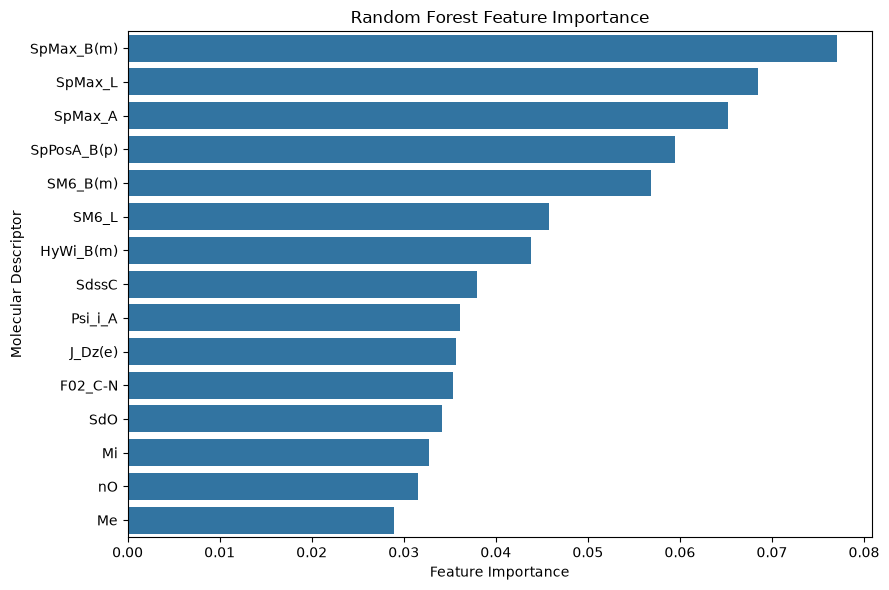

In [19]:
# feature importance


feature_importance_rf = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=feature_importance_rf.head(15).values,
    y=feature_importance_rf.head(15).index
)

plt.xlabel("Feature Importance")
plt.ylabel("Molecular Descriptor")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## Model #4 XGBoost

In [20]:
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)

# Training ROC-AUC
y_train_pred = model_xgb.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, y_train_pred)

# Validation ROC-AUC
y_val_pred = model_xgb.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_pred)

print(f"Training ROC-AUC: {train_auc:.4f}")
print(f"Validation ROC-AUC: {val_auc:.4f}")


Training ROC-AUC: 0.9936
Validation ROC-AUC: 0.9121


we now tune hyperparameters. There are 3 important ones:L

- n_estimators
- max_depth
- learning_rates

We will test 27 configurations

In [21]:

results_xgb = []

for n_estimators in [50, 100, 200]:
    for depth in [2, 3, 5]:
        for lr in [0.03, 0.1, 0.3]:

            model = XGBClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                learning_rate=lr,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train, y_train)

            # Training ROC-AUC
            y_train_pred = model.predict_proba(X_train)[:, 1]
            train_auc = roc_auc_score(y_train, y_train_pred)

            # Validation ROC-AUC
            y_val_pred = model.predict_proba(X_val)[:, 1]
            val_auc = roc_auc_score(y_val, y_val_pred)

            results_xgb.append({
                "n_estimators": n_estimators,
                "max_depth": depth,
                "learning_rate": lr,
                "train_auc": train_auc,
                "val_auc": val_auc
            })

df_results_xgb = pd.DataFrame(results_xgb)

df_results_xgb = df_results_xgb.sort_values(
    "val_auc", ascending=False
)

display(df_results_xgb.head(10))


,n_estimators,max_depth,learning_rate,train_auc,val_auc
7,50,5,0.10,0.998233,0.914784
8,50,5,0.30,1.000000,0.912554
13,100,3,0.10,0.993589,0.912149
12,100,3,0.03,0.971912,0.912048
20,200,2,0.30,0.999966,0.911744
24,200,5,0.03,0.998750,0.911541
14,100,3,0.30,1.000000,0.911339
16,100,5,0.10,0.999944,0.911237
15,100,5,0.03,0.993955,0.911035
4,50,3,0.10,0.981149,0.910984


In [22]:
# select best xgboost

best_params_xgb = df_results_xgb.iloc[0]

best_n_xgb = int(best_params_xgb["n_estimators"])
best_depth_xgb = int(best_params_xgb["max_depth"])
best_lr_xgb = float(best_params_xgb["learning_rate"])
best_xgb_auc = float(best_params_xgb["val_auc"])

best_xgb = XGBClassifier(
    n_estimators=best_n_xgb,
    max_depth=best_depth_xgb,
    learning_rate=best_lr_xgb,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(X_train, y_train)

print("Best parameters:")
print(f"n_estimators: {best_n_xgb}")
print(f"max_depth: {best_depth_xgb}")
print(f"learning_rate: {best_lr_xgb}")

print(f"\nBest validation ROC-AUC: {best_xgb_auc:.4f}")


Best parameters:
n_estimators: 50
max_depth: 5
learning_rate: 0.1

Best validation ROC-AUC: 0.9148


In [23]:
# comparison

model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "val_auc": best_lr_auc
    },
    {
        "model": "Decision Tree",
        "val_auc": float(best_params_dt["val_auc"])
    },
    {
        "model": "Random Forest",
        "val_auc": best_rf_auc
    },
    {
        "model": "XGBoost",
        "val_auc": best_xgb_auc
    }
])

model_comparison = model_comparison.sort_values(
    "val_auc", ascending=False
).reset_index(drop=True)

display(model_comparison)


,model,val_auc
0,Logistic Regression,0.920357
1,Random Forest,0.920306
2,XGBoost,0.914784
3,Decision Tree,0.848718


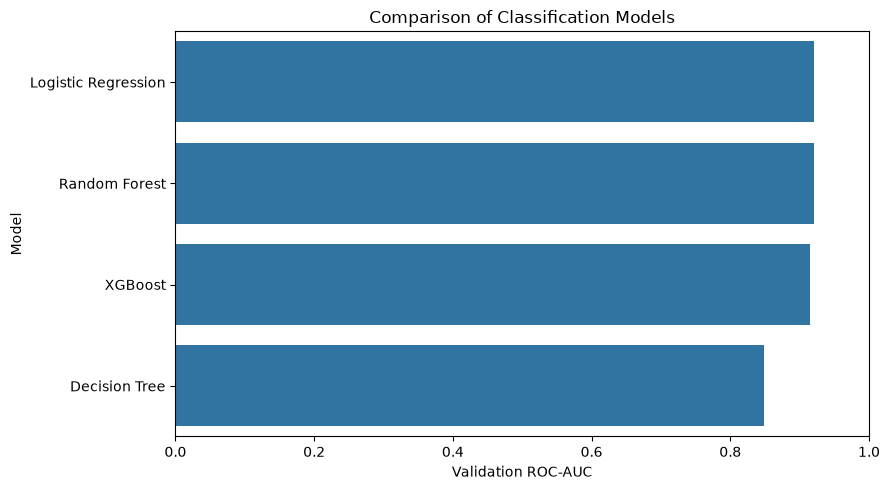

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="val_auc",
    y="model"
)

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Comparison of Classification Models")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

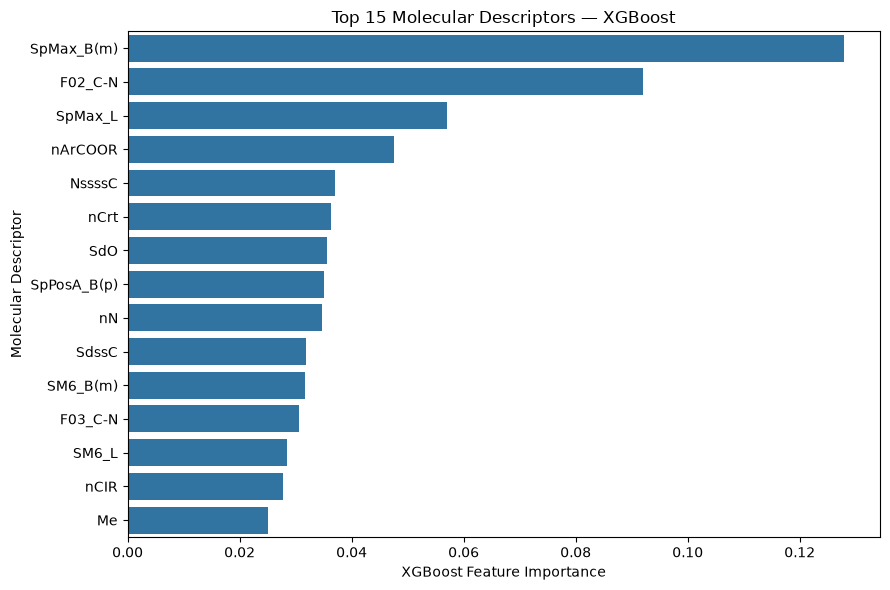

In [25]:
# feature importance
feature_importance_xgb = pd.Series(
    best_xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=feature_importance_xgb.head(15).values,
    y=feature_importance_xgb.head(15).index
)

plt.xlabel("XGBoost Feature Importance")
plt.ylabel("Molecular Descriptor")
plt.title("Top 15 Molecular Descriptors — XGBoost")
plt.tight_layout()
plt.show()

## Model Selection, combined training, and test set

From the above, we see that basic logistic regression just barely beats out random forest as the best model. We choose that, with regularization controlled by $C=1$.

Final Test Results
------------------
ROC-AUC:   0.9040
Accuracy:  0.8673
Precision: 0.8308
Recall:    0.7606
F1-score:  0.7941


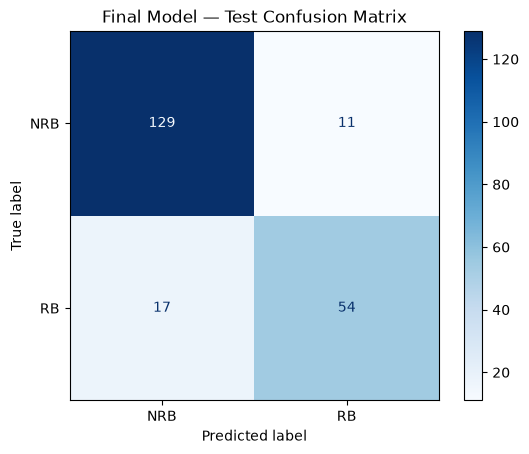

In [27]:
# Combine training and validation data
X_full_train = pd.concat([X_train, X_val])
y_full_train = pd.concat([y_train, y_val])

# Train selected model
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    )
)

final_model.fit(X_full_train, y_full_train)

# Final test-set predictions
y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Evaluation
print("Final Test Results")
print("------------------")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_test_pred):.4f}")

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["NRB", "RB"],
    cmap="Blues"
)

plt.title("Final Model — Test Confusion Matrix")
plt.show()
